# Finance Transactions: Python Analysis

**Question:** Revenue fell about 13% in 2024 while expenses rose about 13%. Where did the change come from, and is it a real trend or normal month-to-month noise?

The SQL and Excel parts of this project showed *what* happened. This notebook digs into *why*, using pandas for the cleaning, the analysis and the charts.

Run it from the `python/` folder. It reads `../data/raw/company_finance_transactions.csv`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
from scipy import stats

try:
    from IPython.display import display
except ImportError:
    display = print

plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e5e5e5', 'axes.axisbelow': True,
})
REV, EXP, NEG = '#2a5db0', '#d9822b', '#c0392b'
K = mt.FuncFormatter(lambda v, _: f'{v/1000:.0f}K')
os.makedirs('figures', exist_ok=True)

## 1. Load the raw data and inspect it

In [2]:
raw = pd.read_csv('../data/raw/company_finance_transactions.csv', parse_dates=['date'])
print('rows:', len(raw))
print('exact duplicate rows:', raw.duplicated().sum())
print('missing values:', int(raw.isna().sum().sum()), '| negative amounts:', int((raw.amount < 0).sum()))
print('department spellings:', sorted(raw.department.unique()))
print('region spellings:', sorted(raw.region.unique()))

rows: 1190
exact duplicate rows: 15
missing values: 0 | negative amounts: 0
department spellings: ['Finance', 'HR', 'IT', 'Marketing', 'Operations', 'R&D', 'Sales', 'finance', 'hr', 'it', 'marketing', 'operations', 'r&d']
region spellings: [' East ', ' North ', ' West ', 'East', 'North', 'South', 'West']


## 2. Clean it (the same rules as the SQL `clean_transactions` view)

Duplicates are removed, department names are standardised (`hr` and `HR` become `HR`) and extra spaces in region names are trimmed. The last line checks that the result matches the SQL-cleaned file.

In [3]:
def clean_department(s):
    s = s.strip()
    return s.upper() if s.lower() in ('hr', 'it', 'r&d') else s.title()

df = raw.copy()
df['department'] = df['department'].map(clean_department)
for col in ['region', 'type', 'category']:
    df[col] = df[col].str.strip()
df['region'] = df['region'].str.title()
df = df.drop_duplicates().sort_values('date').reset_index(drop=True)

df['year'] = df.date.dt.year
df['month'] = df.date.dt.to_period('M').dt.to_timestamp()
df['signed'] = np.where(df.type == 'Revenue', df.amount, -df.amount)

sql_clean = pd.read_csv('../data/cleaned/company_finance_transactions_clean.csv')
print('rows after cleaning:', len(df), '| same row count as SQL:', len(df) == len(sql_clean))
print('same total amount as SQL:', np.isclose(df.amount.sum(), sql_clean.amount.sum()))

rows after cleaning: 1175 | same row count as SQL: True
same total amount as SQL: True


## 3. Headline numbers

In [4]:
rev = df.loc[df.type == 'Revenue', 'amount'].sum()
exp = df.loc[df.type == 'Expense', 'amount'].sum()
kpi = pd.Series({'Revenue': rev, 'Expense': exp, 'Net profit': rev - exp, 'Margin %': (rev - exp) / rev * 100})
display(kpi.round(1))

Revenue       2325409.8
Expense       1019538.4
Net profit    1305871.4
Margin %           56.2
dtype: float64


## 4. Monthly trend

The dashed line is a 3-month rolling average of revenue, which smooths the month-to-month swings so the direction is easier to see.

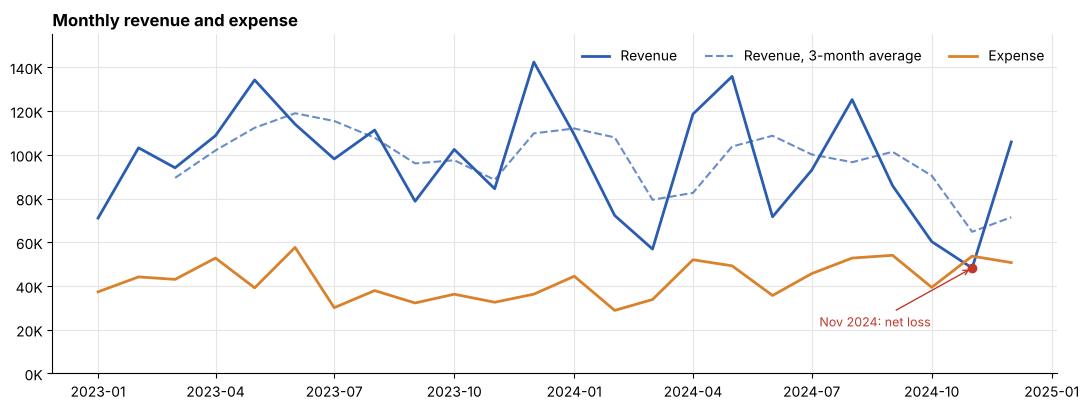

In [5]:
m = df.pivot_table(index='month', columns='type', values='amount', aggfunc='sum')
m['net'] = m.Revenue - m.Expense

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(m.index, m.Revenue, color=REV, lw=2, label='Revenue')
ax.plot(m.index, m.Revenue.rolling(3).mean(), color=REV, lw=1.5, ls='--', alpha=.7, label='Revenue, 3-month average')
ax.plot(m.index, m.Expense, color=EXP, lw=2, label='Expense')
loss = m[m.net < 0]
ax.scatter(loss.index, loss.Revenue, color=NEG, zorder=5)
for d_, r_ in loss.iterrows():
    ax.annotate(f'{d_:%b %Y}: net loss', (d_, r_.Revenue), xytext=(-110, -42), textcoords='offset points',
                color=NEG, fontsize=9, arrowprops=dict(arrowstyle='->', color=NEG))
ax.set_ylim(0, 155000); ax.yaxis.set_major_formatter(K)
ax.set_title('Monthly revenue and expense', loc='left', fontweight='bold')
ax.legend(frameon=False, ncol=3, loc='upper right')
fig.tight_layout(); fig.savefig('figures/01_monthly_trend.png'); plt.show()

## 5. Year over year: volume or value?

Is revenue down because each deal is smaller, or because there are fewer deals? The same question applies to the rise in expenses.

In [6]:
def yearly(t):
    s = df[df.type == t].groupby('year').amount
    return pd.DataFrame({'total': s.sum(), 'transactions': s.count(), 'avg_size': s.mean()})

rev_y, exp_y = yearly('Revenue'), yearly('Expense')
summary = pd.DataFrame({
    'Revenue change %': (rev_y.loc[2024] / rev_y.loc[2023] - 1) * 100,
    'Expense change %': (exp_y.loc[2024] / exp_y.loc[2023] - 1) * 100,
}).round(1)
print('Revenue by year'); display(rev_y.round(0))
print('Expense by year'); display(exp_y.round(0))
print('Change 2023 to 2024 (%)'); display(summary)

Revenue by year
          total  transactions  avg_size
year                                   
2023  1242654.0           272    4569.0
2024  1082756.0           232    4667.0
Expense by year
         total  transactions  avg_size
year                                  
2023  479354.0           314    1527.0
2024  540184.0           357    1513.0
Change 2023 to 2024 (%)
              Revenue change %  Expense change %
total                    -12.9              12.7
transactions             -14.7              13.7
avg_size                   2.2              -0.9


**Reading:** revenue total fell 13%, the number of revenue transactions fell about 15% (272 to 232), and the average deal size actually rose about 2%. So the drop is a **volume** problem: fewer deals, not smaller deals. Expenses rose for the opposite reason: about 14% more expense transactions (314 to 357) at an almost unchanged average size.

## 6. Where did revenue fall?

year                   2023      2024   change  change_pct
category                                                  
Product Sales      316391.0  238484.0 -77907.0       -25.0
Licensing          288922.0  236565.0 -52357.0       -18.0
Consulting         363353.0  340926.0 -22428.0        -6.0
Service Contracts  273988.0  266781.0  -7207.0        -3.0


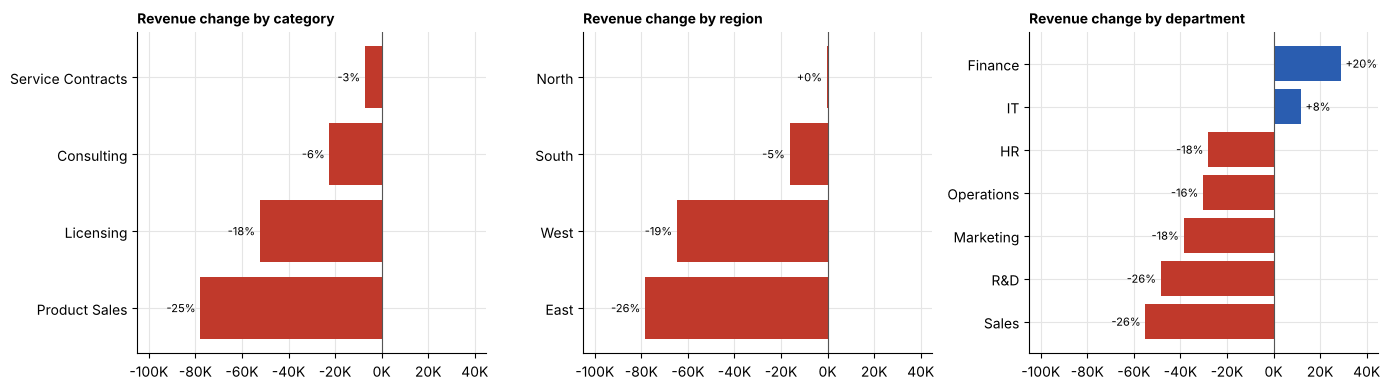

In [7]:
r = df[df.type == 'Revenue']
def change_by(col):
    p = r.pivot_table(index=col, columns='year', values='amount', aggfunc='sum')
    p['change'] = p[2024] - p[2023]
    p['change_pct'] = p.change / p[2023] * 100
    return p.sort_values('change')

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True)
for ax, col in zip(axes, ['category', 'region', 'department']):
    c = change_by(col)
    ax.barh(c.index, c.change, color=[NEG if v < 0 else REV for v in c.change])
    ax.axvline(0, color='#555', lw=.8)
    ax.set_title(f'Revenue change by {col}', loc='left', fontweight='bold', fontsize=10)
    ax.xaxis.set_major_formatter(K); ax.set_xlim(-105000, 45000)
    for i, (v, pct) in enumerate(zip(c.change, c.change_pct)):
        ax.text(v + (2000 if v >= 0 else -2000), i, f'{int(round(pct)):+d}%', va='center',
                ha='left' if v >= 0 else 'right', fontsize=8)
fig.tight_layout(); fig.savefig('figures/02_revenue_change_drivers.png'); plt.show()
display(change_by('category').round(0))

**Reading:**
- By category, **Product Sales (-25%)** and **Licensing (-18%)** account for most of the loss.
- By region, **East (-26%)** and **West (-19%)** fell the most, while **North** was flat.
- By department, **Sales and R&D (-26% each)** fell the most, while **IT (+8%)** and **Finance (+20%)** grew.

These are the places to investigate first.

## 7. Where did expenses rise?

year                2023     2024   change
category                                  
Salaries         75043.0  48990.0 -26053.0
Equipment        79016.0  69468.0  -9548.0
Travel           66907.0  67701.0    795.0
Office Supplies  72189.0  86377.0  14188.0
Software         68414.0  93023.0  24608.0
Utilities        52920.0  78251.0  25331.0
Marketing Spend  64864.0  96373.0  31509.0


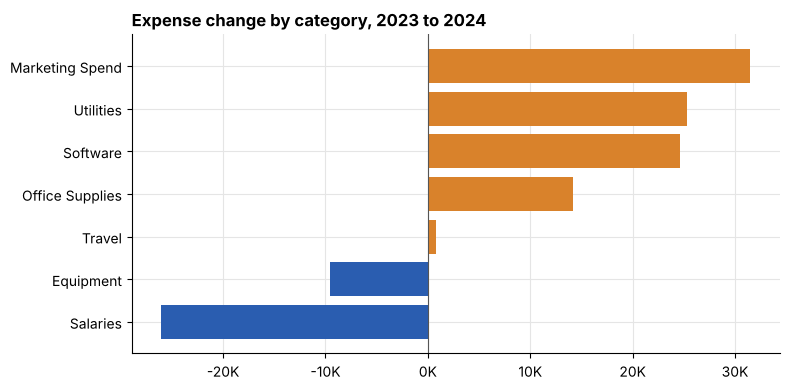

In [8]:
e = df[df.type == 'Expense']
p = e.pivot_table(index='category', columns='year', values='amount', aggfunc='sum')
p['change'] = p[2024] - p[2023]
p = p.sort_values('change')

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(p.index, p.change, color=[REV if v < 0 else EXP for v in p.change])
ax.axvline(0, color='#555', lw=.8)
ax.xaxis.set_major_formatter(K)
ax.set_title('Expense change by category, 2023 to 2024', loc='left', fontweight='bold')
fig.tight_layout(); fig.savefig('figures/03_expense_change_drivers.png'); plt.show()
display(p.round(0))

**Reading:** the increase comes from **Marketing Spend (+31K), Utilities (+25K) and Software (+25K)**. Salaries went down by 26K, which hides part of the rise.

## 8. Is the 2024 revenue drop statistically significant?

With only 12 monthly values per year and large month-to-month swings, a 13% gap could be noise. Two tests check this: Welch's t-test (compares means) and the Mann-Whitney U test (rank-based, makes no normality assumption).

In [9]:
monthly_rev = m.Revenue
y23 = monthly_rev[monthly_rev.index.year == 2023]
y24 = monthly_rev[monthly_rev.index.year == 2024]

t = stats.ttest_ind(y23, y24, equal_var=False)
u = stats.mannwhitneyu(y23, y24)
print(f'mean monthly revenue 2023: {y23.mean():,.0f} | 2024: {y24.mean():,.0f} | difference: {y23.mean()-y24.mean():,.0f}')
print(f'std of monthly revenue 2023: {y23.std():,.0f} | 2024: {y24.std():,.0f}')
print(f'Welch t-test p-value: {t.pvalue:.3f}')
print(f'Mann-Whitney p-value: {u.pvalue:.3f}')

mean monthly revenue 2023: 103,554 | 2024: 90,230 | difference: 13,325
std of monthly revenue 2023: 20,892 | 2024: 28,892
Welch t-test p-value: 0.210
Mann-Whitney p-value: 0.312


**Reading:** both p-values (about 0.21 and 0.31) are well above 0.05. With this little data, the 2024 revenue decline **cannot be distinguished from normal month-to-month variation**. It is worth investigating, but it should not be presented as a confirmed trend. More months of data would settle it.

## 9. Outliers

Large transactions can distort totals. The check flags amounts above Q3 + 1.5 x IQR within each type.

In [10]:
grp = df.groupby('type').amount
q1 = grp.transform(lambda s: s.quantile(.25))
q3 = grp.transform(lambda s: s.quantile(.75))
df['outlier'] = df.amount > q3 + 1.5 * (q3 - q1)
print(df.groupby('type').outlier.agg(['sum', 'mean']).rename(columns={'sum': 'outliers', 'mean': 'share'}).round(3))
print('Largest transactions:')
display(df.nlargest(5, 'amount')[['date', 'department', 'region', 'type', 'category', 'amount']])

         outliers  share
type                    
Expense        20  0.030
Revenue        13  0.026
Largest transactions:
          date  department region     type           category    amount
244 2023-05-26  Operations   West  Revenue          Licensing  14286.81
174 2023-04-20     Finance   West  Revenue          Licensing  13931.33
880 2024-07-05         R&D   West  Revenue  Service Contracts  13575.94
427 2023-09-24  Operations   East  Revenue         Consulting  13297.79
324 2023-07-14       Sales   West  Revenue         Consulting  13247.66


**Reading:** about 3% of transactions in each type are flagged (20 expenses and 13 revenue transactions). The largest amounts are all revenue deals, which is normal for right-skewed revenue. Nothing looks like a data error (no negative or zero amounts), so the outliers are kept in the analysis.

## 10. Profit margin by department and region

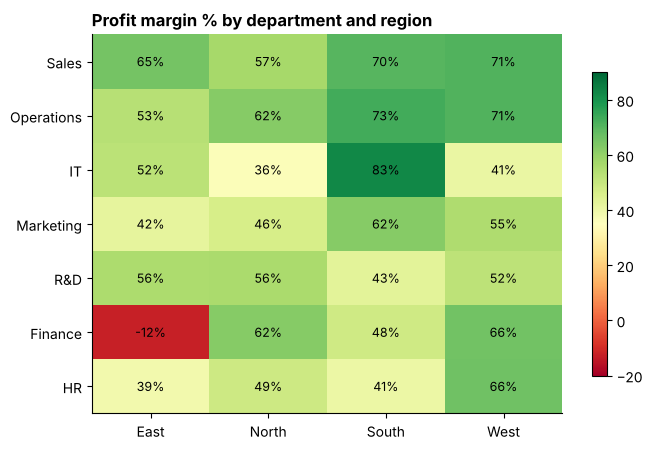

In [11]:
g = df.pivot_table(index='department', columns=['region'], values=['signed'], aggfunc='sum')['signed']
rv = df[df.type == 'Revenue'].pivot_table(index='department', columns='region', values='amount', aggfunc='sum')
margin = (g / rv * 100)
order = (g.sum(axis=1) / rv.sum(axis=1)).sort_values(ascending=False).index
margin = margin.loc[order]

fig, ax = plt.subplots(figsize=(7, 4.6))
im = ax.imshow(margin.values, cmap='RdYlGn', vmin=-20, vmax=90, aspect='auto')
ax.set_xticks(range(margin.shape[1])); ax.set_xticklabels(margin.columns)
ax.set_yticks(range(margin.shape[0])); ax.set_yticklabels(margin.index)
ax.grid(False)
for i in range(margin.shape[0]):
    for j in range(margin.shape[1]):
        ax.text(j, i, f'{margin.values[i, j]:.0f}%', ha='center', va='center', fontsize=9)
ax.set_title('Profit margin % by department and region', loc='left', fontweight='bold')
fig.colorbar(im, ax=ax, shrink=.8)
fig.tight_layout(); fig.savefig('figures/04_margin_heatmap.png'); plt.show()

## 11. Conclusions

1. The company is profitable (56% margin), but 2024 revenue fell 13% and expenses rose 13%.
2. The revenue fall is a **volume** problem (about 15% fewer revenue transactions), concentrated in **Product Sales, Licensing, the East and West regions, and the Sales and R&D departments**.
3. The expense rise is also volume-driven, led by **Marketing Spend, Utilities and Software**.
4. With 24 months of data, the revenue decline is **not statistically significant** (p about 0.2 to 0.3). Treat it as a warning sign to monitor, not a proven trend.
5. Finance-East is the weakest combination (a loss), and East has the lowest margin overall.

### Next steps
- Get more history (at least 3 to 5 years) to separate trend from seasonality.
- Look at deal counts per month in Product Sales and Licensing to see when the volume dropped.
- Compare Marketing Spend against revenue by month to test whether it pays back.